In [1]:
import pandas as pd
import numpy as np

# Heavy installments

In [2]:
!pip install pytorch-tabnet scikit-learn pandas numpy
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score
import torch
import torch.nn as nn
import torch.optim as optim
# DESVIACIÓN 1 (entorno): rtdl exige torch<2, incompatible con Colab actual
# (Python 3.13, torch 2.14). FT-Transformer pospuesto. Fecha: 09/11/2026
# !pip install rtdl
# import rtdl
!pip install tabpfn==2.0.8
from tabpfn import TabPFNClassifier

In [3]:
!pip show tabpfn | head -3
!python --version

Name: tabpfn
Version: 2.0.8
Summary: TabPFN: Foundation model for tabular data
ERROR: Pipe to stdout was broken
Python 3.13.18


# Data Preparation

In [4]:
df = pd.read_csv('/content/combined_statslogExcluded_SMOTE_GenderBalancedWithCTGAN.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
0,54,1,1,122,193,0,1,162,0,1.328331,1,0
1,40,0,4,150,392,0,0,130,0,2.000000,2,1
2,74,1,1,145,216,1,0,116,1,1.800000,2,1
3,46,1,4,110,236,0,0,125,1,2.000000,2,1
4,57,1,4,140,192,0,0,148,0,0.400000,2,0


In [5]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols_to_scale = df.drop('target',axis=1).columns.to_list()
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
0,0.361860,1.0,-2.372673,-0.629625,-0.100252,-0.547876,0.54235,0.824905,-0.816717,-0.067029,-1.081518,0
1,-0.912294,-1.0,0.808772,0.477018,1.636802,-0.547876,-0.70773,-0.411813,-0.816717,0.336797,0.577886,1
2,2.182082,1.0,-2.372673,0.279403,0.100513,1.825229,-0.70773,-0.952877,1.224414,0.216551,0.577886,1
3,-0.366228,1.0,0.808772,-1.103900,0.275091,-0.547876,-0.70773,-0.605050,1.224414,0.336797,0.577886,1
4,0.634894,1.0,0.808772,0.081788,-0.108981,-0.547876,-0.70773,0.283841,-0.816717,-0.625168,0.577886,0


In [6]:
from sklearn.model_selection import train_test_split
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y, test_size=0.2,random_state=123)

In [7]:
print(df.shape, X_train.shape, X_test.shape)

(1542, 12) (1233, 11) (309, 11)


In [ ]:
# Convert to numpy arrays
X_train_np, y_train_np = X_train.values, y_train
X_test_np, y_test_np = X_test.values, y_test

# TabNet

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.6/386.6 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 17.2 MB/s eta 0:00:00


In [ ]:
from sklearn.metrics import accuracy_score
import optuna


# Convert to numpy arrays
X_train_np, y_train_np = X_train.values, y_train
X_test_np, y_test_np = X_test.values, y_test

def objective(trial):
    params = {
        "n_d": trial.suggest_int("n_d", 8, 64),
        "n_a": trial.suggest_int("n_a", 8, 64),
        "n_steps": trial.suggest_int("n_steps", 3, 10),
        "gamma": trial.suggest_float("gamma", 1.0, 2.0),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-5, 1e-1, log=True),
        "optimizer_params": dict(lr=trial.suggest_float("lr", 1e-4, 1e-1, log=True)),
        "mask_type": trial.suggest_categorical("mask_type", ["entmax", "sparsemax"]),
        "scheduler_params": {"step_size": 10, "gamma": 0.9},
        "scheduler_fn": torch.optim.lr_scheduler.StepLR,
        "seed": 42,
        "verbose": 0
    }

    model = TabNetClassifier(**params)

    model.fit(
        X_train=X_train_np, y_train=y_train_np,
        eval_set=[(X_test_np, y_test_np)],
        eval_name=["valid"],
        eval_metric=["accuracy"],
        max_epochs=100,
        patience=10,
        batch_size=1024,
        virtual_batch_size=128,
        num_workers=0,
        drop_last=False
    )

    preds = model.predict(X_test_np)
    acc = accuracy_score(y_test_np, preds)
    return acc

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

print("Best Hyperparameters:", study.best_params)
print("Best Accuracy:", study.best_value)


[I 2025-04-19 13:33:35,575] A new study created in memory with name: no-name-fc99a0cb-1072-4a52-88d0-15710836512e
/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-19 13:33:54,663] Trial 0 finished with value: 0.8737864077669902 and parameters: {'n_d': 46, 'n_a': 35, 'n_steps': 6, 'gamma': 1.394157712687546, 'lambda_sparse': 0.0489341268072747, 'lr': 0.07165975730681114, 'mask_type': 'sparsemax'}. Best is trial 0 with value: 0.8737864077669902.



Early stopping occurred at epoch 35 with best_epoch = 25 and best_valid_accuracy = 0.87379


/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-19 13:34:03,903] Trial 1 finished with value: 0.8996763754045307 and parameters: {'n_d': 56, 'n_a': 60, 'n_steps': 3, 'gamma': 1.9235308308010224, 'lambda_sparse': 0.00032844522512283716, 'lr': 0.0056606881415474635, 'mask_type': 'entmax'}. Best is trial 1 with value: 0.8996763754045307.



Early stopping occurred at epoch 36 with best_epoch = 26 and best_valid_accuracy = 0.89968


/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-19 13:34:13,513] Trial 2 finished with value: 0.8349514563106796 and parameters: {'n_d': 22, 'n_a': 28, 'n_steps': 3, 'gamma': 1.7301003845123133, 'lambda_sparse': 9.158760625597816e-05, 'lr': 0.0002928951017632541, 'mask_type': 'sparsemax'}. Best is trial 1 with value: 0.8996763754045307.



Early stopping occurred at epoch 63 with best_epoch = 53 and best_valid_accuracy = 0.83495


... (44 outputs left out)

/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-19 13:38:36,831] Trial 28 finished with value: 0.889967637540453 and parameters: {'n_d': 41, 'n_a': 54, 'n_steps': 3, 'gamma': 1.6809530601593585, 'lambda_sparse': 0.04070187409666214, 'lr': 0.0031638316904329983, 'mask_type': 'entmax'}. Best is trial 16 with value: 0.9061488673139159.



Early stopping occurred at epoch 52 with best_epoch = 42 and best_valid_accuracy = 0.88997


/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-19 13:38:45,231] Trial 29 finished with value: 0.86084142394822 and parameters: {'n_d': 33, 'n_a': 41, 'n_steps': 5, 'gamma': 1.41494728767116, 'lambda_sparse': 4.706053176376122e-05, 'lr': 0.06743560447809095, 'mask_type': 'sparsemax'}. Best is trial 16 with value: 0.9061488673139159.



Early stopping occurred at epoch 31 with best_epoch = 21 and best_valid_accuracy = 0.86084
Best Hyperparameters: {'n_d': 33, 'n_a': 44, 'n_steps': 4, 'gamma': 1.3131023975379672, 'lambda_sparse': 0.010714170784219094, 'lr': 0.09667119524841804, 'mask_type': 'entmax'}
Best Accuracy: 0.9061488673139159


In [12]:
import torch
from pytorch_tabnet.tab_model import TabNetClassifier

X_train_np, y_train_np = X_train.values, y_train
X_test_np, y_test_np = X_test.values, y_test
print(X_train_np.shape, X_test_np.shape)

(1233, 11) (309, 11)


In [13]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

In [18]:
tabnet = TabNetClassifier(
    n_d=33,
    n_a=44,
    n_steps=4,
    gamma=1.3131023975379672,  # Using full precision to replicate best score
    lambda_sparse=0.010714170784219094,
    optimizer_fn=torch.optim.Adam,
    optimizer_params={'lr': 0.09667119524841804},
    mask_type='entmax'
)

# Train the model
tabnet.fit(
    X_train_np, y_train_np,
    eval_set=[(X_test_np, y_test_np)],
    patience=10, max_epochs=100,
    batch_size=48, virtual_batch_size=32
)

# Make predictions on test set
y_pred = tabnet.predict(X_test_np)

# Show classification report on test set
print(classification_report(y_test_np, y_pred))



/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.67648 | val_0_auc: 0.87265 |  0:00:03s
epoch 1  | loss: 0.41612 | val_0_auc: 0.89326 |  0:00:04s
epoch 2  | loss: 0.39183 | val_0_auc: 0.91852 |  0:00:05s
epoch 3  | loss: 0.37577 | val_0_auc: 0.91535 |  0:00:05s
epoch 4  | loss: 0.40136 | val_0_auc: 0.93096 |  0:00:06s
epoch 5  | loss: 0.39406 | val_0_auc: 0.92728 |  0:00:07s
epoch 6  | loss: 0.37721 | val_0_auc: 0.92913 |  0:00:08s
epoch 7  | loss: 0.35856 | val_0_auc: 0.91813 |  0:00:08s
epoch 8  | loss: 0.3449  | val_0_auc: 0.92226 |  0:00:09s
epoch 9  | loss: 0.34029 | val_0_auc: 0.91898 |  0:00:10s
epoch 10 | loss: 0.37569 | val_0_auc: 0.92967 |  0:00:11s
epoch 11 | loss: 0.35371 | val_0_auc: 0.91893 |  0:00:11s
epoch 12 | loss: 0.34871 | val_0_auc: 0.93648 |  0:00:12s
epoch 13 | loss: 0.32812 | val_0_auc: 0.94841 |  0:00:13s
epoch 14 | loss: 0.32095 | val_0_auc: 0.93663 |  0:00:14s
epoch 15 | loss: 0.33968 | val_0_auc: 0.92778 |  0:00:15s
epoch 16 | loss: 0.32475 | val_0_auc: 0.9342  |  0:00:16s
epoch 17 | los

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


              precision    recall  f1-score   support

           0       0.85      0.88      0.87       125
           1       0.92      0.90      0.91       184

    accuracy                           0.89       309
   macro avg       0.88      0.89      0.89       309
weighted avg       0.89      0.89      0.89       309



In [19]:
print(accuracy_score(y_test_np, y_pred))
print(f1_score(y_test_np, y_pred))

0.889967637540453
0.9065934065934066


In [20]:
import pandas as pd

proba = tabnet.predict_proba(X_test_np)[:, 1]
out = pd.DataFrame({
    "row_id": X_test.index,
    "y_true": y_test.values,
    "y_pred": y_pred,
    "proba_1": proba,
    "model": "TabNet_author_params",
    "protocol": "author_split_rs123_leaky",
})
out.to_csv("preds_tabnet.csv", index=False)
print(out.shape, (out.y_pred == out.y_true).mean())

(309, 6) 0.889967637540453


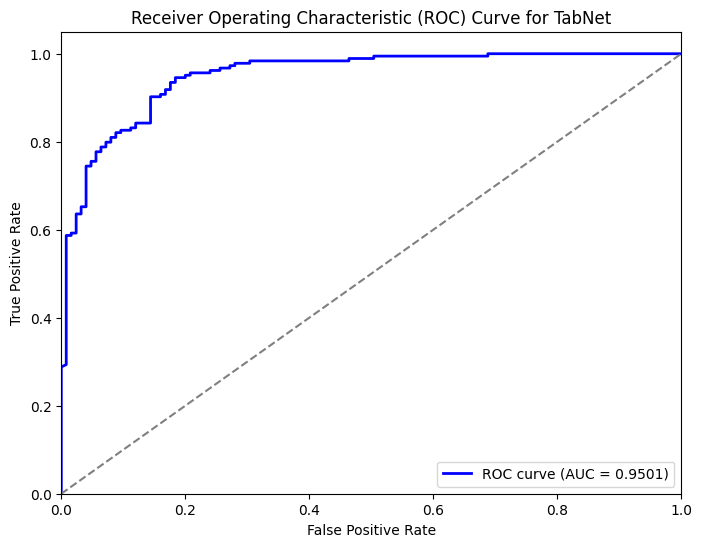

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities for the positive class (class 1)
y_proba_tabnet = tabnet.predict_proba(X_test_np)[:, 1]

# Compute ROC curve and ROC AUC
fpr_tabnet, tpr_tabnet, thresholds_tabnet = roc_curve(y_test_np, y_proba_tabnet)
roc_auc_tabnet = auc(fpr_tabnet, tpr_tabnet)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_tabnet, tpr_tabnet, color='b', lw=2, label=f'ROC curve (AUC = {roc_auc_tabnet:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for TabNet')
plt.legend(loc='lower right')
plt.show()


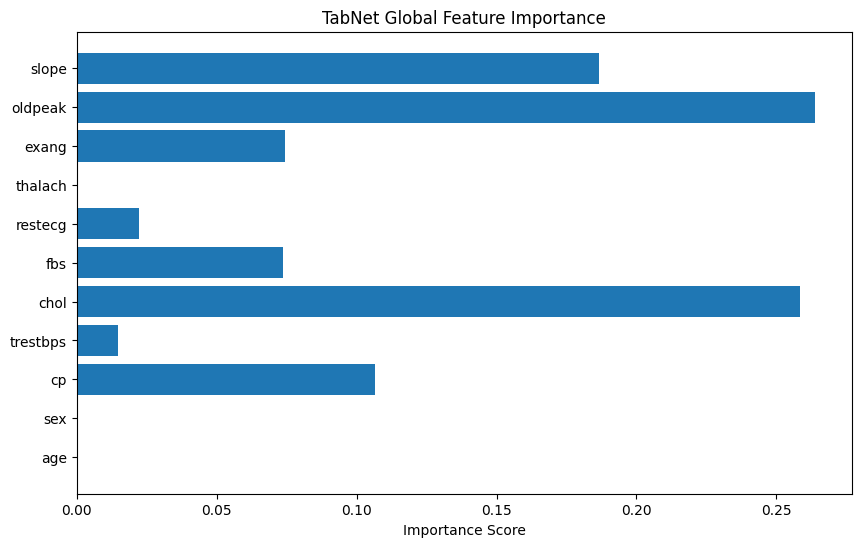

In [ ]:
# Get global feature importance (aggregated over all training data)
feature_importances = tabnet.feature_importances_

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(X.columns, feature_importances)
plt.title("TabNet Global Feature Importance")
plt.xlabel("Importance Score")
plt.show()

In [ ]:
# Select a sample patient from X_test (e.g., first row)
patient_df = X_test.iloc[[0]]  # Double brackets keep it as a DataFrame

pred = tabnet.predict(patient_df.values)
print("Predicted class:", pred[0])


Predicted class: 1


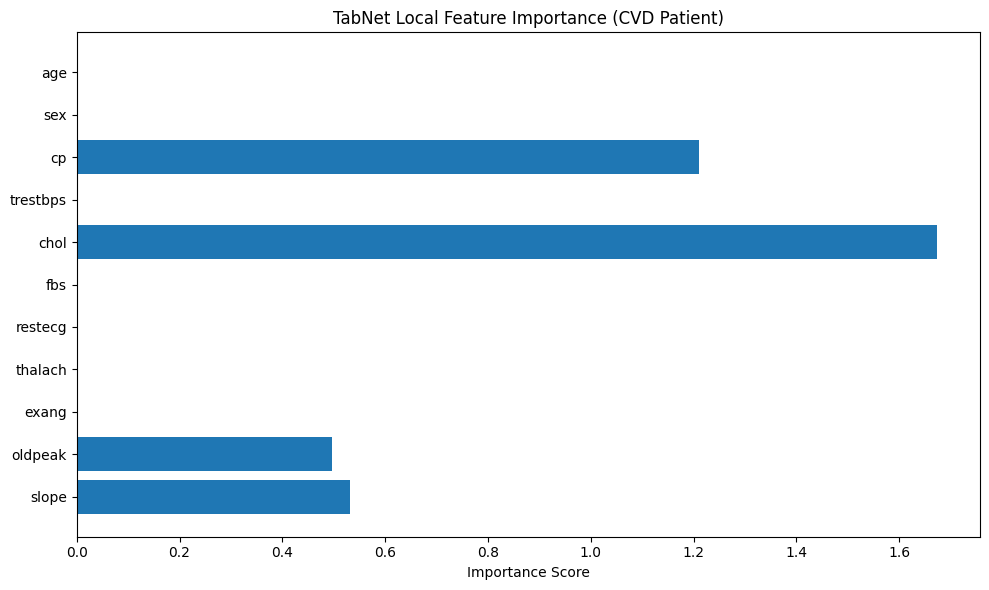

In [ ]:
import matplotlib.pyplot as plt

# Explain prediction
explain_matrix, masks = tabnet.explain(patient_df.values)

# Get local importance scores
local_importance = explain_matrix[0]  # First (and only) sample

# Plot
plt.figure(figsize=(10, 6))
plt.barh(X_test.columns, local_importance)
plt.title("TabNet Local Feature Importance (CVD Patient)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()  # Optional: feature names top to bottom
plt.tight_layout()
plt.show()


In [ ]:
# Select a sample patient from X_test (e.g., first row)
patient_df = X_test.iloc[[1]]  # Double brackets keep it as a DataFrame

pred = tabnet.predict(patient_df.values)
print("Predicted class:", pred[0])


Predicted class: 0


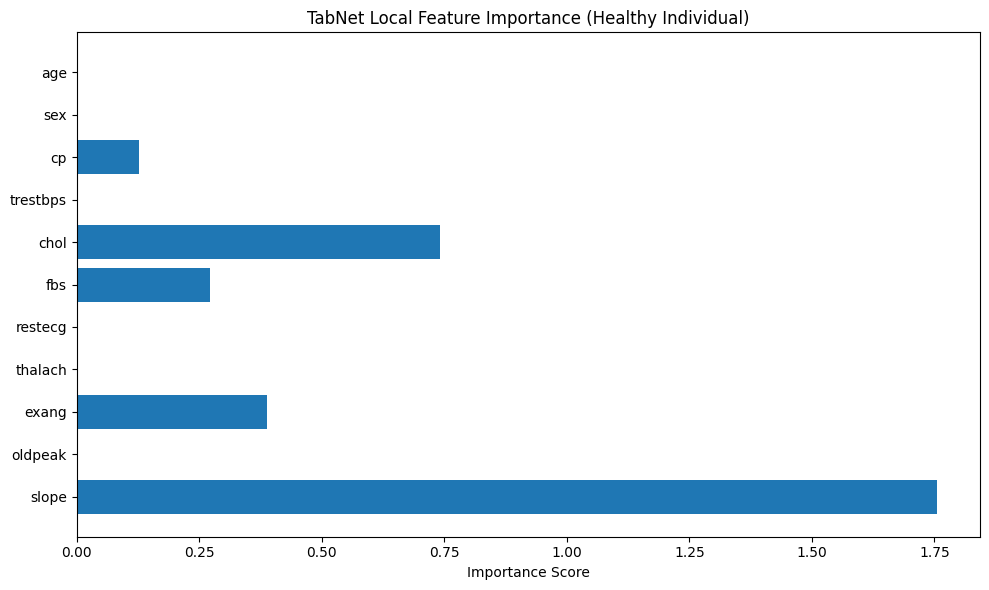

In [ ]:

# Explain prediction
explain_matrix, masks = tabnet.explain(patient_df.values)

# Get local importance scores
local_importance = explain_matrix[0]  # First (and only) sample

# Plot
plt.figure(figsize=(10, 6))
plt.barh(X_test.columns, local_importance)
plt.title("TabNet Local Feature Importance (Healthy Individual)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()  # Optional: feature names top to bottom
plt.tight_layout()
plt.show()


In [ ]:
import shap

In [ ]:

def f(x):
    return tabnet.predict_proba(x)[:, 1]


med = X_train.median().values.reshape((1, X_train.shape[1]))

explainer = shap.Explainer(f, med)
shap_values = explainer(X_test.iloc[0:1000, :])


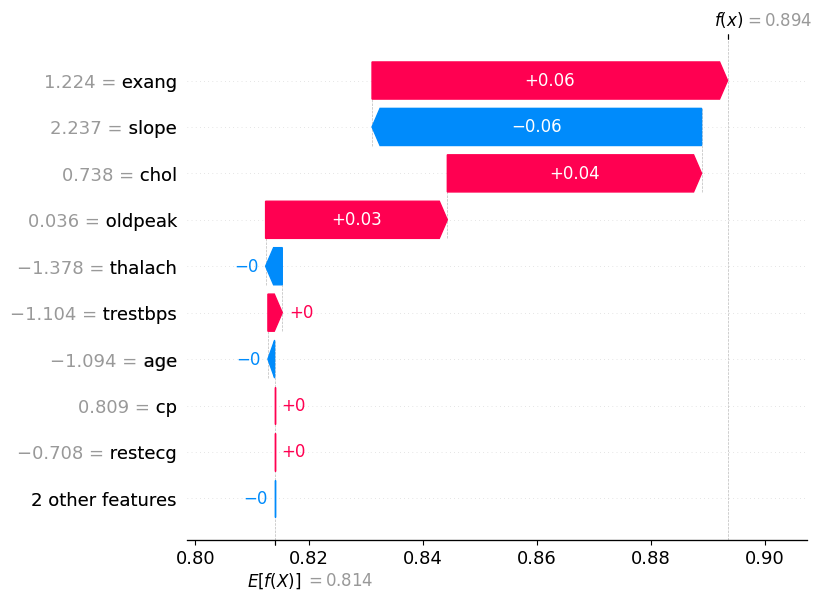

In [ ]:
shap.plots.waterfall(shap_values[0])

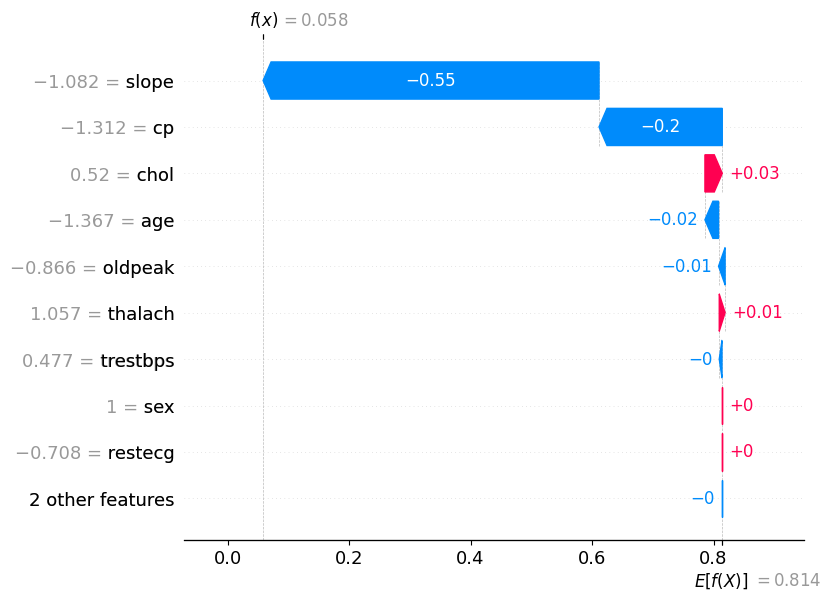

In [ ]:
shap.plots.waterfall(shap_values[1])

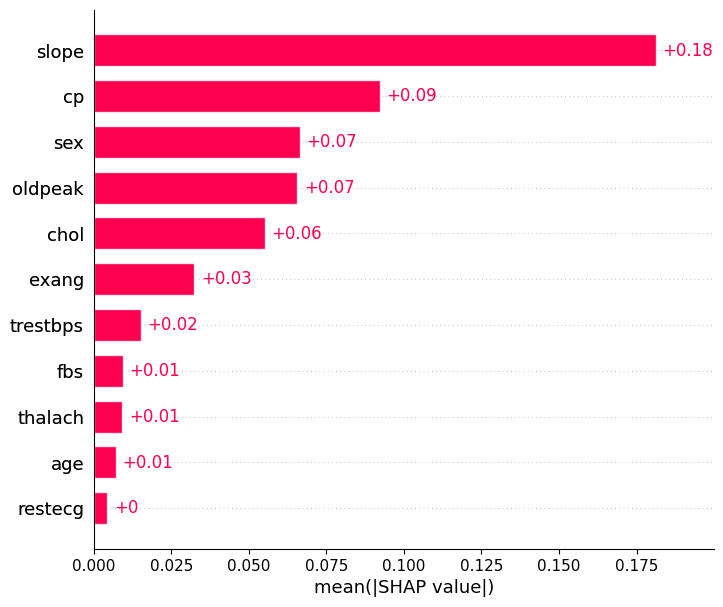

In [ ]:
# Bar plot of mean(|SHAP value|) per feature
shap.plots.bar(shap_values, max_display=11)

# FT-Transformer

In [ ]:
import numpy as np

# Convert data to PyTorch tensors
X_train_torch = torch.tensor(X_train.values, dtype=torch.float32)
X_test_torch = torch.tensor(X_test.values, dtype=torch.float32)
y_train_torch = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_test_torch = torch.tensor(y_test.to_numpy(), dtype=torch.long)

# Define FT-Transformer model
model = rtdl.FTTransformer.make_default(
    n_num_features=X_train.shape[1],  # Number of input features
    cat_cardinalities=None,  # No categorical features
    d_out=len(np.unique(y_train))  # Number of classes
)

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Loss function & optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Training loop
epochs = 50
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    # Pass `None` for categorical input since we only have numerical features
    y_pred = model(X_train_torch.to(device), x_cat=None)

    loss = criterion(y_pred, y_train_torch.to(device))
    loss.backward()
    optimizer.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch}/{epochs}, Loss: {loss.item():.4f}")

# Evaluation
model.eval()
with torch.no_grad():
    y_pred_test = model(X_test_torch.to(device), x_cat=None).argmax(dim=1).cpu().numpy()

# Print classification report

print(classification_report(y_test, y_pred_test))
print(accuracy_score(y_test, y_pred_test))
print(f1_score(y_test, y_pred_test))


NameError: name 'rtdl' is not defined

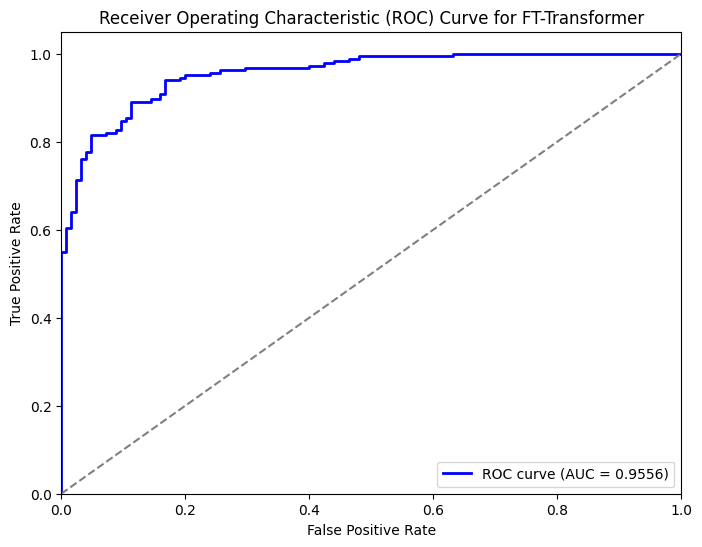

In [ ]:
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import torch.nn.functional as F


# Get predicted probabilities for the positive class (class 1)
model.eval()  # Set model to evaluation mode
with torch.no_grad():
    y_pred = model(X_test_torch, x_cat=None)  # Get logits for the test data
    y_pred_probs = F.softmax(y_pred, dim=1)[:, 1]  # Get probabilities for the positive class (class 1)

# Calculate ROC curve and ROC AUC
fpr, tpr, thresholds = roc_curve(y_test_torch.cpu(), y_pred_probs.cpu())
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='b', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for FT-Transformer')
plt.legend(loc='lower right')
plt.show()


# TabPFN

In [10]:
import os
from google.colab import userdata
os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")
os.environ["TABPFN_ALLOW_CPU_LARGE_DATASET"] = "1"

# Initialize the TabPFN model
model = TabPFNClassifier(device="cpu")  # Use "cuda" if you have a GPU

# Train the model (TabPFN trains instantly, no need for epochs)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Show classification report

print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred))
print(f1_score(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.91      0.84      0.87       125
           1       0.90      0.94      0.92       184

    accuracy                           0.90       309
   macro avg       0.90      0.89      0.89       309
weighted avg       0.90      0.90      0.90       309

0.8996763754045307
0.9177718832891246


In [22]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred))
print(f1_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.88      0.87       125
           1       0.92      0.90      0.91       184

    accuracy                           0.89       309
   macro avg       0.88      0.89      0.89       309
weighted avg       0.89      0.89      0.89       309

0.889967637540453
0.9065934065934066


In [11]:
import pandas as pd
out = pd.DataFrame({
    "row_id": X_test.index,
    "y_true": y_test.values,
    "y_pred": y_pred,
    "proba_1": model.predict_proba(X_test)[:, 1],
    "model": "TabPFN_v9.2.0_weights_v3.5",
    "protocol": "author_split_rs123_leaky",
})
out.to_csv("preds_tabpfn_A2.csv", index=False)

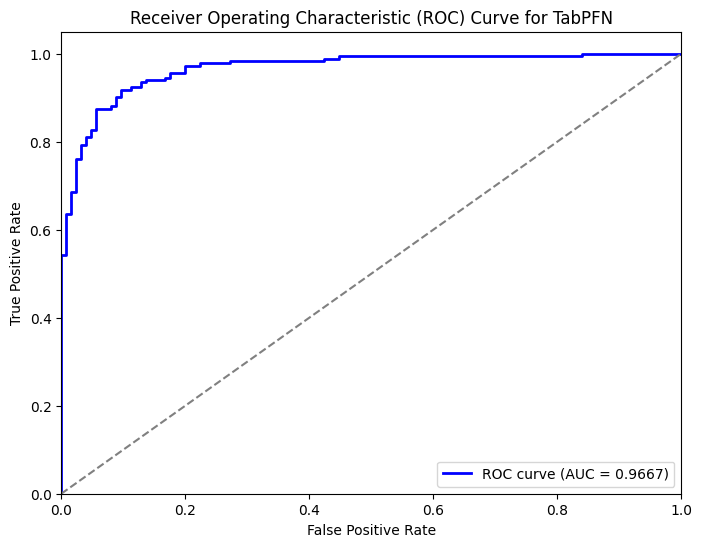

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities for the positive class (class 1)
y_proba_tabpfn = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and ROC AUC
fpr_tabpfn, tpr_tabpfn, thresholds_tabpfn = roc_curve(y_test, y_proba_tabpfn)
roc_auc_tabpfn = auc(fpr_tabpfn, tpr_tabpfn)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_tabpfn, tpr_tabpfn, color='b', lw=2, label=f'ROC curve (AUC = {roc_auc_tabpfn:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for TabPFN')
plt.legend(loc='lower right')
plt.show()


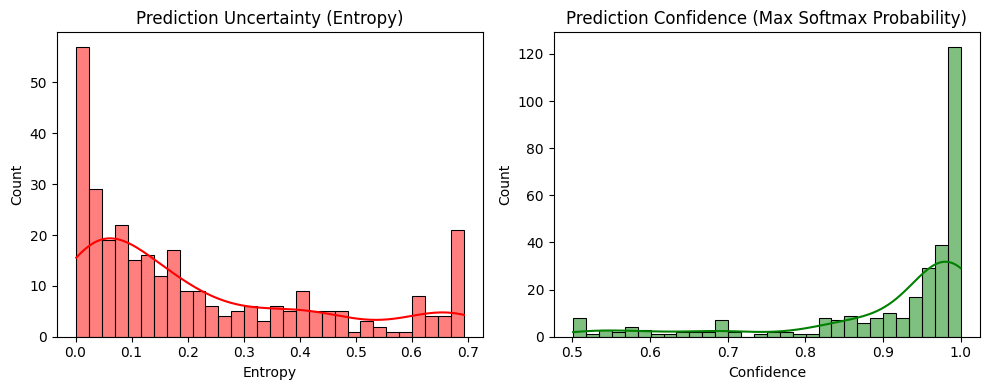

In [ ]:

# Get predicted probabilities for test set
y_proba = model.predict_proba(X_test)

##### COMPUTE ENTROPY AND CONFIDENCE ########
import numpy as np

# Entropy: measure of uncertainty
def compute_entropy(probs):
    return -np.sum(probs * np.log(probs + 1e-9), axis=1)  # small epsilon for numerical stability

# Confidence: 1 - uncertainty
def compute_confidence(probs):
    return np.max(probs, axis=1)

entropies = compute_entropy(y_proba)
confidences = compute_confidence(y_proba)

####### VISUALIZE #######
import matplotlib.pyplot as plt
import seaborn as sns

# Plot histogram of entropy (uncertainty)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(entropies, bins=30, kde=True, color='red')
plt.title("Prediction Uncertainty (Entropy)")
plt.xlabel("Entropy")
plt.ylabel("Count")

# Plot histogram of confidence
plt.subplot(1, 2, 2)
sns.histplot(confidences, bins=30, kde=True, color='green')
plt.title("Prediction Confidence (Max Softmax Probability)")
plt.xlabel("Confidence")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


# BNN

In [ ]:
# Convert data to numpy arrays and ensure proper shape
X_train_np = X_train.values.astype(np.float32)
y_train_np = y_train.values.astype(np.float32)
X_test_np = X_test.values.astype(np.float32)
y_test_np = y_test.values.astype(np.float32)

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report
import numpy as np

In [ ]:
# Define Bayesian Neural Network using MC Dropout
def build_mc_dropout_model(input_dim):
    model = keras.Sequential([
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.2),  # Dropout for Bayesian Approximation
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

# Initialize model
input_dim = X_train.shape[1]
bnn_model = build_mc_dropout_model(input_dim)

# Train model
bnn_model.fit(X_train_np, y_train_np, epochs=500, batch_size=32, verbose=1)

# Number of MC samples
num_samples = 1000

# Perform MC Dropout (make multiple predictions)
y_pred_samples = np.array([bnn_model(X_test_np, training=True).numpy().flatten() for _ in range(num_samples)])

# Calculate mean and standard deviation (uncertainty) of predictions
y_pred_mean = y_pred_samples.mean(axis=0)  # Mean prediction for each sample
y_pred_std = y_pred_samples.std(axis=0)   # Standard deviation as uncertainty

# Convert to binary predictions (PCOS or not) by thresholding at 0.5
y_pred_binary = (y_pred_mean > 0.5).astype(int)



Epoch 1/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6834 - loss: 0.5899
Epoch 2/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8737 - loss: 0.3223
Epoch 3/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8910 - loss: 0.2824
Epoch 4/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8943 - loss: 0.2761
Epoch 5/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8996 - loss: 0.2666
Epoch 6/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8982 - loss: 0.2687
Epoch 7/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9126 - loss: 0.2534
Epoch 8/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9162 - loss: 0.2457
Epoch 9/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9147 - loss: 0.2575
Epoch 10/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9106 - loss: 0.2532
Epoch 11/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9060 - loss: 0.2333
Epoch 12/500
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy:

In [ ]:
# Classification report
print("Classification Report:")
print(classification_report(y_test_np, y_pred_binary))

# Example: Display the uncertainty (std) for the first 5 samples
print("\nUncertainty (Standard Deviation) for First 5 Samples:")
print(y_pred_std[:5])  # Print uncertainty for the first 5 test samples

print(accuracy_score(y_test_np, y_pred_binary))
print(f1_score(y_test_np, y_pred_binary))

Classification Report:
              precision    recall  f1-score   support

         0.0       0.86      0.81      0.83       125
         1.0       0.87      0.91      0.89       184

    accuracy                           0.87       309
   macro avg       0.87      0.86      0.86       309
weighted avg       0.87      0.87      0.87       309


Uncertainty (Standard Deviation) for First 5 Samples:
[0.03870961 0.02963952 0.25355262 0.03863842 0.03734227]
0.8673139158576052
0.8906666666666667


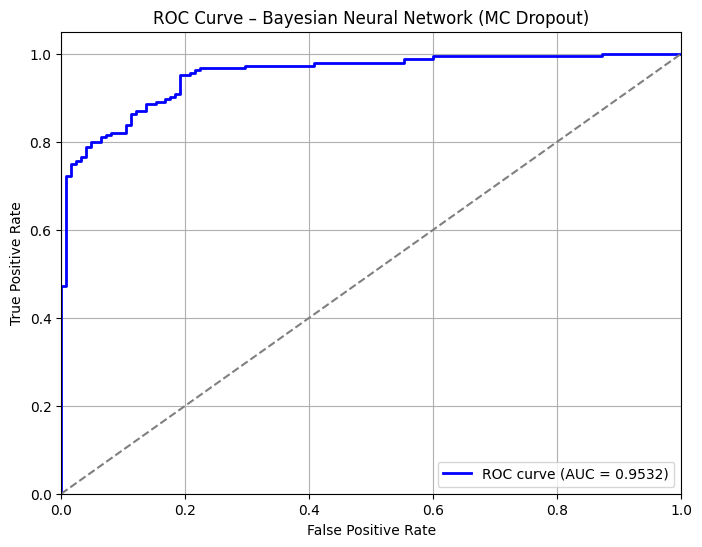

ROC-AUC Score: 0.9532


In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Use the mean predictions from MC samples for ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test_np, y_pred_mean)
roc_auc = auc(fpr, tpr)

# Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='b', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Bayesian Neural Network (MC Dropout)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")


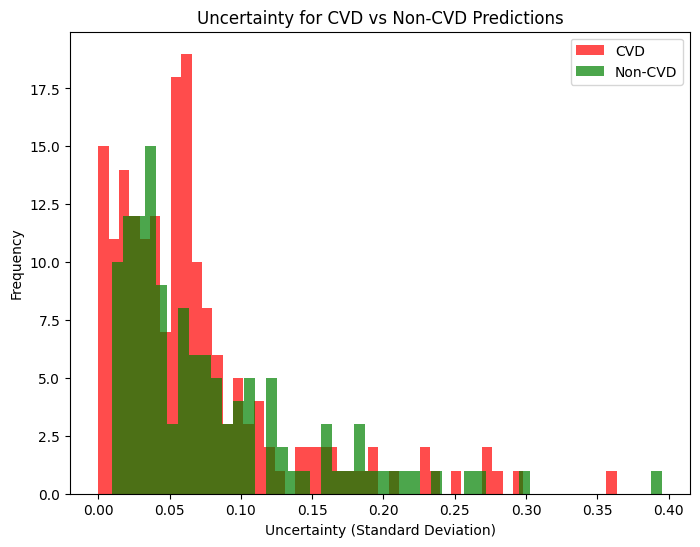

In [ ]:
# Plot predictions (mean) vs uncertainty (std)
import matplotlib.pyplot as plt
# Plot uncertainty for PCOS (1) vs Non-PCOS (0) predictions
pcos_uncertainty = y_pred_std[y_test_np == 1]  # Uncertainty for CVD cases
non_pcos_uncertainty = y_pred_std[y_test_np == 0]  # Uncertainty for Non-CVD cases

plt.figure(figsize=(8, 6))
plt.hist(pcos_uncertainty, bins=50, alpha=0.7, color='red', label='CVD')
plt.hist(non_pcos_uncertainty, bins=50, alpha=0.7, color='green', label='Non-CVD')

plt.title('Uncertainty for CVD vs Non-CVD Predictions')
plt.xlabel('Uncertainty (Standard Deviation)')
plt.ylabel('Frequency')
plt.legend(loc='upper right')
plt.show()


Predicted class: 1 (Probability: 0.9765, Uncertainty: ±0.0370)


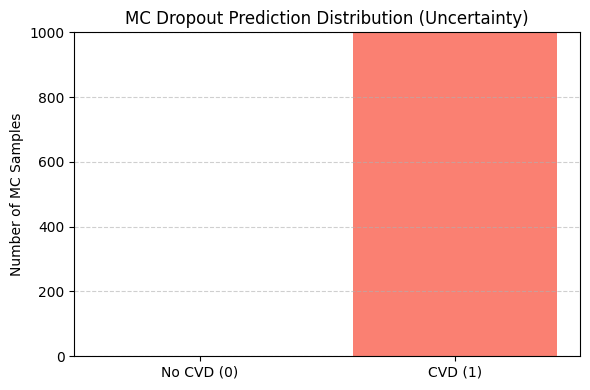

In [ ]:
import numpy as np

# Assume `patient_df` is a DataFrame with a single row (same columns as training data)
# You can select a patient from test set like:
patient_df = X_test.iloc[[0]]  # double brackets keep it a DataFrame

# Convert to NumPy
patient_np = patient_df.values

# Number of Monte Carlo samples for uncertainty estimation
num_mc_samples = 1000

# Get multiple stochastic predictions
patient_preds = np.array([
    bnn_model(patient_np, training=True).numpy().flatten()[0]
    for _ in range(num_mc_samples)
])

# Mean prediction (probability of class 1)
mean_pred = patient_preds.mean()

# Standard deviation (uncertainty)
std_pred = patient_preds.std()

# Binary prediction
binary_pred = int(mean_pred > 0.5)

print(f"Predicted class: {binary_pred} (Probability: {mean_pred:.4f}, Uncertainty: ±{std_pred:.4f})")

# Get binary class predictions from MC samples
binary_preds = (patient_preds > 0.5).astype(int)

# Count occurrences of each class
class_0_count = np.sum(binary_preds == 0)
class_1_count = np.sum(binary_preds == 1)

# Plotting
plt.figure(figsize=(6, 4))
plt.bar(['No CVD (0)', 'CVD (1)'], [class_0_count, class_1_count], color=['skyblue', 'salmon'])
plt.title("MC Dropout Prediction Distribution (Uncertainty)")
plt.ylabel("Number of MC Samples")
plt.ylim(0, num_mc_samples)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


Predicted class: 0 (Probability: 0.0168, Uncertainty: ±0.0438)


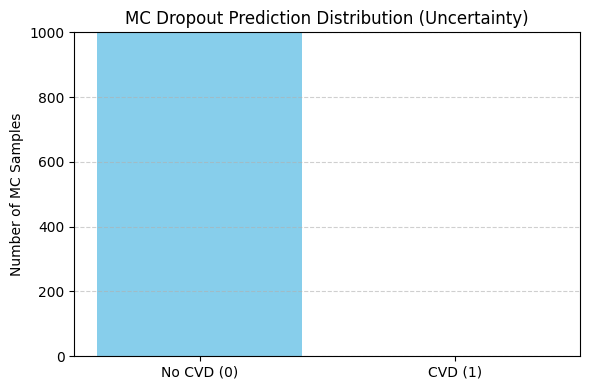

In [ ]:
import numpy as np

# Assume `patient_df` is a DataFrame with a single row (same columns as training data)
# You can select a patient from test set like:
patient_df = X_test.iloc[[1]]  # double brackets keep it a DataFrame

# Convert to NumPy
patient_np = patient_df.values

# Number of Monte Carlo samples for uncertainty estimation
num_mc_samples = 1000

# Get multiple stochastic predictions
patient_preds = np.array([
    bnn_model(patient_np, training=True).numpy().flatten()[0]
    for _ in range(num_mc_samples)
])

# Mean prediction (probability of class 1)
mean_pred = patient_preds.mean()

# Standard deviation (uncertainty)
std_pred = patient_preds.std()

# Binary prediction
binary_pred = int(mean_pred > 0.5)

print(f"Predicted class: {binary_pred} (Probability: {mean_pred:.4f}, Uncertainty: ±{std_pred:.4f})")

# Get binary class predictions from MC samples
binary_preds = (patient_preds > 0.5).astype(int)

# Count occurrences of each class
class_0_count = np.sum(binary_preds == 0)
class_1_count = np.sum(binary_preds == 1)

# Plotting
plt.figure(figsize=(6, 4))
plt.bar(['No CVD (0)', 'CVD (1)'], [class_0_count, class_1_count], color=['skyblue', 'salmon'])
plt.title("MC Dropout Prediction Distribution (Uncertainty)")
plt.ylabel("Number of MC Samples")
plt.ylim(0, num_mc_samples)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


Next: How would these models perform on Gaussian Copula augmented dataset?
https://colab.research.google.com/drive/1NBe0NirCsf-68UjmJXaYqZyu2F2InFx9?usp=sharing

# Next: Causal inference and voting modeling: https://colab.research.google.com/drive/1iKTXCDyvLg-MjmVhYhY8uMvoltykGe0H?usp=sharing